# Proyecto Final Integrador
## Detección de fraude en transacciones financieras móviles

**Diplomado en Ciencia de Datos y Análisis Avanzado - UTN.BA - Unidad 9**

Este proyecto propone construir un modelo de clasificación que asigne un puntaje de riesgo de fraude a transacciones financieras, con el objetivo de priorizar qué operaciones deben revisarse manualmente.
La **problemática** surge de una situación habitual en auditoría, riesgo y compliance: la necesidad de revisar un gran volumen de operaciones e identificar aquellas transacciones que presentan una mayor probabilidad de irregularidad.
El dataset utilizado es **PaySim - “Synthetic Financial Datasets For Fraud Detection”**, disponible en Kaggle. PaySim es un simulador de transacciones de dinero móvil construido a partir de patrones agregados y anonimizados de un servicio real, con fraude inyectado de forma controlada para fines de entrenamiento de modelos (Lopez-Rojas, Elmir y Axelsson, 2016).

**Características del dataset**
- 6.362.620 transacciones.
- 11 variables por transacción.
- Cobertura temporal: 743 steps, equivalentes a casi 31 días simulados, donde 1 step representa 1 hora.
- Transacciones fraudulentas: 8.213.
- Proporción de fraude: 0,129% del total.
- Distribución de clases: 99,87% de las transacciones son legítimas y 0,13% fraudulentas, evidenciando un fuerte desbalance de clases.

**Objetivo**
Construir un modelo de clasificación binaria capaz de predecir si una transacción es fraudulenta (isFraud = 1) o legítima (isFraud = 0), utilizando las características disponibles de la operación.
El modelo no busca únicamente clasificar las transacciones, sino asignar un nivel de riesgo que permita ordenar las operaciones y priorizar aquellas que deberían ser revisadas manualmente.

**KPI de impacto esperado:** El objetivo operativo definido para el proyecto es:
Alcanzar un recall ≥ 0,80 sobre los casos de fraude reales, manteniendo la revisión manual en ≤ 5% del total de transacciones.
De esta manera, el modelo deberá lograr detectar al menos el 80% de los fraudes reales sin generar un volumen de operaciones para revisión que supere la capacidad definida para el proceso manual.

**Integrantes:**
Axel Bojko
Joaquín Bousono
Josefina Martínez
Rocío Esposito
Romina Obregón

**Reproducibilidad**
Para garantizar la reproducibilidad de los resultados se utilizará una semilla fija:
random_state = 42
Las salidas generadas durante el análisis se almacenarán en la carpeta:
results/

## Metodología

Este notebook reproduce los números del informe final siguiendo CRISP-DM:

1. **Comprensión del negocio:** KPI (recall ≥ 0,80 revisando ≤ 5 % de las transacciones) y métricas.
2. **Comprensión de los datos:** exploración de PaySim, calidad de datos y riesgos de fuga de información.
3. **Preparación:** variables conocidas antes de la transacción, historial del destinatario y partición temporal 60/20/20 por `step`.
4. **Modelado:** regresión logística, Random Forest y XGBoost, con ponderación de clases y con submuestreo; selección por PR-AUC en validación.
5. **Evaluación:** test temporal, una sola vez, contra revisión al azar y una regla simple de auditoría.
6. **Sensibilidad:** fraudes y monto capturados según el nivel de revisión.
7. **Interpretabilidad:** SHAP.
8. **Profundización:** ablaciones, estabilidad por día, prevalencia real, ranking por pérdida esperada y auditoría por grupos.
9. **Escenario económico** con supuestos explícitos.
10. **Ética, privacidad y limitaciones.**
11. **Despliegue y monitoreo.**
12. **Resumen y conclusión.**


In [1]:
# Instala dependencias solo si faltan (útil en Google Colab)
import importlib.util, subprocess, sys
for pkg in ['xgboost', 'shap']:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_recall_curve)
from xgboost import XGBClassifier
import shap

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RANDOM_STATE = 42
K = 0.05                      # capacidad de revisión manual: 5 % de las transacciones
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
print('pandas', pd.__version__, '| shap', shap.__version__)

pandas 2.2.3 | shap 0.54.1


## 1. Comprensión del negocio: KPI y métricas

Un equipo de auditoría/riesgo necesita priorizar qué transacciones revisar manualmente debido al enorme volumen de operaciones, prediciendo la probabilidad de que una transacción sea fraudulenta.

**KPI principal**
Recall ≥ 0,80 sobre los fraudes reales, manteniendo:
≤ 5% de las transacciones enviadas a revisión.

Dado que menos del 0,2% de las transacciones son fraude, la métrica de accuracy no es informativa, porque el fuerte desbalance de clases podría generar un valor elevado incluso en un modelo que no detectara ningún fraude. Se priorizarán:
**Recall@5%:** de todos los fraudes reales, qué porcentaje queda dentro del 5% de transacciones con mayor riesgo según el modelo. Es la medida directa del KPI y el costo de no detectar un fraude real (falso negativo) es mayor que el de revisar de más una transacción legítima (falso positivo).
**PR-AUC (Average Precision):** para evaluar qué tan bien el modelo ordena los fraudes por encima de las transacciones legítimas. Su valor de referencia (piso) es la tasa de fraude del tramo evaluado, no 0,5.
**AUC-ROC:** como complemento, para evaluar la capacidad general de discriminación.
**Precision@5%, Lift@5% y F1-score:** como métricas secundarias, para monitorear que no se generen demasiados falsos positivos que saturen la capacidad de revisión manual del equipo de auditoría.

Como referencia se compara contra una revisión al azar, que con el 5% de las transacciones detectaría en promedio el 5% de los fraudes.

La evaluación es temporal: se entrena con los primeros steps y se evalúa en los últimos. Como el volumen de transacciones legítimas cae mucho después del día 18 mientras los fraudes se mantienen, la tasa de fraude del tramo de test (1,34%) es mayor que la del total (0,129%). Por eso las métricas se leen siempre contra su piso y contra la revisión al azar.

In [3]:
def top_k_mask(y_score, k=K):
    # Marca como "a revisar" al k % con mayor score (desempate estable)
    y_score = np.asarray(y_score)
    n = max(1, int(np.ceil(len(y_score) * k)))
    mask = np.zeros(len(y_score), dtype=bool)
    mask[np.argsort(-y_score, kind='mergesort')[:n]] = True
    return mask

def recall_at_k(y_true, y_score, k=K):
    y_true = np.asarray(y_true); pos = y_true.sum()
    return float(y_true[top_k_mask(y_score, k)].sum() / pos) if pos else np.nan

def metrics(y_true, score, k=K):
    y_true = np.asarray(y_true); m = top_k_mask(score, k)
    prec = y_true[m].mean()
    return {'PR_AUC': average_precision_score(y_true, score),
            'ROC_AUC': roc_auc_score(y_true, score),
            'Recall@5': recall_at_k(y_true, score, k),
            'Precision@5': prec,
            'Lift@5': prec / y_true.mean(),
            'F1@5': f1_score(y_true, m.astype(int))}

## 2.Comprensión de los datos

En esta etapa se realizará un análisis exploratorio del dataset PaySim para evaluar su estructura, calidad y características, con especial atención a la identificación de transacciones fraudulentas.

Se analizarán los tipos de variables, la presencia de valores nulos y duplicados, la distribución de la variable objetivo (isFraud) y las posibles relaciones entre el fraude y las características de las transacciones.

Además, se evaluarán posibles inconsistencias y riesgos de data leakage que deban considerarse antes de preparar los datos para el modelado.


In [4]:
# Cargar el dataset (se descarga de Kaggle si no está en la carpeta)
import os, subprocess, sys
from getpass import getpass

DATA_DIR = "/content" if os.path.exists("/content") else "data"
os.makedirs(DATA_DIR, exist_ok=True)
RUTA = os.path.join(DATA_DIR, "PS_20174392719_1491204439457_log.csv")

if not os.path.exists(RUTA):
    subprocess.run([sys.executable, "-m", "pip", "install", "kaggle", "-q"], check=True)
    if "KAGGLE_USERNAME" not in os.environ:
        os.environ["KAGGLE_USERNAME"] = input("Usuario de Kaggle: ")
    if "KAGGLE_KEY" not in os.environ:
        os.environ["KAGGLE_KEY"] = getpass("API key de Kaggle: ")
    subprocess.run(["kaggle", "datasets", "download", "-d", "ealaxi/paysim1", "-p", DATA_DIR, "--unzip"], check=True)

df = pd.read_csv(RUTA)

# Verificar que se haya cargado correctamente
print("Dimensiones del dataset:", df.shape)  # tiene que dar (6362620, 11)

# Mostrar las primeras filas
display(df.head())

Usuario de Kaggle: marrtinezj
API key de Kaggle: ··········
Dimensiones del dataset: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


In [5]:
print(df.columns.tolist())
print(df.info())


['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB
None


### Calidad de datos: nulos, duplicados, isFlaggedFraud y outliers

In [6]:
# Copia de trabajo para el análisis de calidad (no se vuelve a leer el archivo)
df_raw = df.copy()

print("Dataset cargado correctamente")
print("Dimensiones:", df_raw.shape)
display(df_raw.head())

Dataset cargado correctamente
Dimensiones: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


In [7]:
# Carpeta para guardar resultados
RESULTS = Path("results")
RESULTS.mkdir(parents=True, exist_ok=True)

# Identificar las columnas categóricas
cat_raw = df_raw.select_dtypes(exclude="number").columns

# Revisar nulos y valores "unknown"
quality = pd.DataFrame({
    "nulos": df_raw.isna().sum(),
    "unknown": [
        int((df_raw[c] == "unknown").sum()) if c in cat_raw else 0
        for c in df_raw.columns
    ],
})

quality["unknown_%"] = quality["unknown"] / len(df_raw) * 100

# Mostrar solamente las columnas con problemas
quality = quality[
    (quality["nulos"] > 0) | (quality["unknown"] > 0)
].sort_values("unknown", ascending=False)

# Guardar el informe
quality.to_csv(RESULTS / "eda_calidad.csv")

# Resumen general
print("Dimensiones del dataset:", df_raw.shape)
print("Nulos explícitos totales:", int(df_raw.isna().sum().sum()))
print("Duplicados exactos:", int(df_raw.duplicated().sum()))

print("\nDistribución de la variable objetivo (isFraud):")
print(df_raw["isFraud"].value_counts())

print("\nPorcentaje de fraude:")
print(f"{df_raw['isFraud'].mean():.3%}")

print("\nTransacciones marcadas por el sistema (isFlaggedFraud):")
print(df_raw["isFlaggedFraud"].value_counts())

print("\nColumnas con nulos o valores 'unknown':")
display(quality)

print("\nInforme guardado en:", RESULTS / "eda_calidad.csv")


Dimensiones del dataset: (6362620, 11)
Nulos explícitos totales: 0
Duplicados exactos: 0

Distribución de la variable objetivo (isFraud):
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Porcentaje de fraude:
0.129%

Transacciones marcadas por el sistema (isFlaggedFraud):
isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

Columnas con nulos o valores 'unknown':


,nulos,unknown,unknown_%



Informe guardado en: results/eda_calidad.csv


In [8]:
tipo = df_raw.groupby('type').isFraud.agg(transacciones='size', fraudes='sum', tasa_fraude='mean')
tipo.to_csv(RESULTS / 'eda_tipo.csv')
tipo

,transacciones,fraudes,tasa_fraude
type,,,
CASH_IN,1399284,0,0.0000
CASH_OUT,2237500,4116,0.0018
DEBIT,41432,0,0.0000
PAYMENT,2151495,0,0.0000
TRANSFER,532909,4097,0.0077


In [9]:
cols_num = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
desc = df_raw[cols_num].describe(percentiles=[.5, .95, .99]).T
desc.to_csv(RESULTS / 'eda_montos.csv')
display(desc)

monto_clase = df_raw.groupby('isFraud').amount.agg(['mean', 'median', 'std', 'max'])
monto_clase.to_csv(RESULTS / 'eda_monto_por_clase.csv')
display(monto_clase)

# Proporción de transacciones que vacían la cuenta de origen, según clase
vacia = ((df_raw.amount >= df_raw.oldbalanceOrg) & (df_raw.oldbalanceOrg > 0)).groupby(df_raw.isFraud).mean()
display(vacia.rename('proporción que vacía la cuenta origen'))

,count,mean,std,min,50%,95%,99%,max
amount,"6,362,620.0000","179,861.9035","603,858.2315",0.0000,"74,871.9400","518,634.1965","1,615,979.4716","92,445,516.6400"
oldbalanceOrg,"6,362,620.0000","833,883.1041","2,888,242.6730",0.0000,"14,208.0000","5,823,702.2785","16,027,256.1337","59,585,040.3700"
newbalanceOrig,"6,362,620.0000","855,113.6686","2,924,048.5030",0.0000,0.0000,"5,980,262.3365","16,176,160.5580","49,585,040.3700"
oldbalanceDest,"6,362,620.0000","1,100,701.6665","3,399,180.1130",0.0000,"132,705.6650","5,147,229.7135","12,371,819.1548","356,015,889.3500"
newbalanceDest,"6,362,620.0000","1,224,996.3982","3,674,128.9421",0.0000,"214,661.4400","5,515,715.9035","13,137,866.9410","356,179,278.9200"


,mean,median,std,max
isFraud,,,,
0,"178,197.0417","74,684.7200","596,236.9813","92,445,516.6400"
1,"1,467,967.2991","441,423.4400","2,404,252.9472","10,000,000.0000"


,proporción que vacía la cuenta origen
isFraud,
0,0.3111
1,0.9767


step: de 1 a 743


,transacciones,fraudes,tasa_fraude
step,,,
1,574255,271,0.0005
2,455238,309,0.0007
3,1070,310,0.2897


,transacciones,fraudes,tasa_fraude
step,,,
29,54890,260,0.0047
30,11287,268,0.0237
31,272,272,1.0000


Cuentas distintas en nameOrig: 6353307 de 6362620 transacciones
Cuentas distintas en nameDest: 2722362
Destinatario comercio (empieza con M): 33.8 %


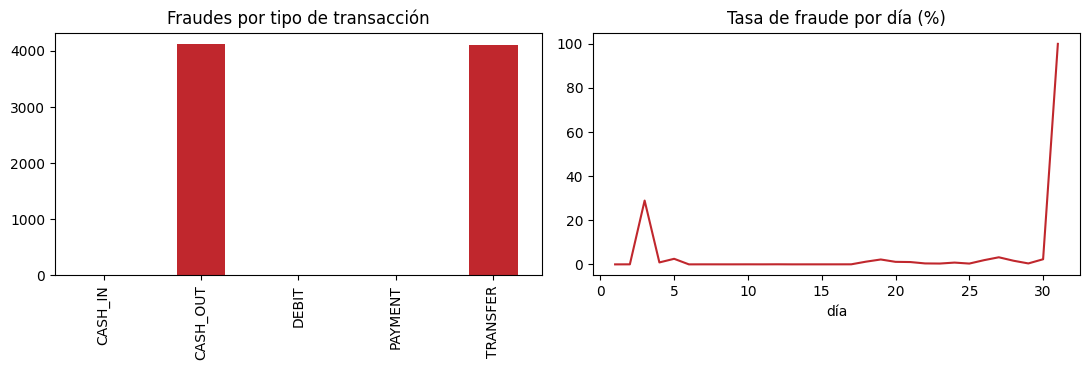

In [10]:
dia = (df_raw.step - 1) // 24 + 1
por_dia = df_raw.groupby(dia).isFraud.agg(transacciones='size', fraudes='sum', tasa_fraude='mean')
por_dia.to_csv(RESULTS / 'eda_fraude_por_dia.csv')
print('step: de', df_raw.step.min(), 'a', df_raw.step.max())
display(por_dia.head(3)); display(por_dia.tail(3))

print('Cuentas distintas en nameOrig:', df_raw.nameOrig.nunique(), 'de', len(df_raw), 'transacciones')
print('Cuentas distintas en nameDest:', df_raw.nameDest.nunique())
print('Destinatario comercio (empieza con M): %.1f %%' % (df_raw.nameDest.str.startswith('M').mean() * 100))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
tipo.fraudes.plot.bar(ax=ax[0], color='#C0272D'); ax[0].set_title('Fraudes por tipo de transacción'); ax[0].set_xlabel('')
(por_dia.tasa_fraude * 100).plot(ax=ax[1], color='#C0272D'); ax[1].set_title('Tasa de fraude por día (%)'); ax[1].set_xlabel('día')
plt.tight_layout(); plt.savefig(RESULTS / 'fig_eda.png', dpi=150); plt.show()

## 3. Preparación de los datos

Decisiones (registradas en `data_log.md`):

| Decisión | Motivo |
|---|---|
| Excluir `newbalanceOrig` y `newbalanceDest` | Se conocen después de la transacción (fuga). |
| Excluir `isFlaggedFraud` | Es salida de una regla del simulador, no dato previo. |
| Excluir `nameOrig` y `nameDest` | Son códigos de cuenta; casi ninguno de origen se repite. |
| Crear `dest_comercio` (`nameDest` empieza con M) | Indica tipo de destinatario, no la cuenta. |
| Crear `vacia_origen` (monto ≥ saldo inicial) | Vaciar la cuenta es un patrón típico de fraude. |
| Crear `hora` (step módulo 24) | Momento del día, sin usar `step`. |
| Crear historial del destinatario | Solo con transacciones previas y sin etiquetas. |
| Partición temporal por `step` 60/20/20 | Se entrena con los primeros días y se evalúa en los últimos. |
| Conservar todas las filas | No hay nulos y se respeta el orden temporal. |

Como la tasa de fraude sube de train (0,08%) a valid (0,68%) y test (1,34%), los modelos se comparan por ranking y siempre contra el piso de cada tramo.

Toda transformación aprendida vive dentro de un `Pipeline`. Si se necesitaran probabilidades absolutas y no solo ranking, habría que evaluar calibración.

In [11]:
# Orden temporal
df = df_raw.sort_values('step', kind='mergesort').reset_index(drop=True)

# Variables conocidas antes de la transacción
df['hora'] = (df.step - 1) % 24
df['vacia_origen'] = (df.amount >= df.oldbalanceOrg).astype(int)
df['dest_comercio'] = df.nameDest.str.startswith('M').astype(int)
df['dest_saldo_cero'] = (df.oldbalanceDest == 0).astype(int)

# Historial del destinatario: solo transacciones anteriores, sin usar etiquetas
g = df.groupby('nameDest')
df['dest_tx_previas'] = g.cumcount()
df['dest_monto_previo'] = g.amount.cumsum() - df.amount

y = df.isFraud
X = df[['type', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'hora', 'vacia_origen',
        'dest_comercio', 'dest_saldo_cero', 'dest_tx_previas', 'dest_monto_previo']]

cat_cols = ['type']
num_cols = [c for c in X.columns if c not in cat_cols]

# Partición temporal 60/20/20 por step
tramo = pd.cut(df.step, [0, 445, 594, 743], labels=['train', 'valid', 'test'])
X_train, y_train = X[tramo == 'train'], y[tramo == 'train']
X_valid, y_valid = X[tramo == 'valid'], y[tramo == 'valid']
X_test,  y_test  = X[tramo == 'test'],  y[tramo == 'test']

print('Variables usadas:', X.columns.tolist())
for nombre, yy in [('train', y_train), ('valid', y_valid), ('test', y_test)]:
    print(f'{nombre}: {len(yy):,} transacciones | {int(yy.sum()):,} fraudes | tasa {yy.mean():.4%}')

def make_pre(scale):
    return ColumnTransformer(
        [('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
         ('num', StandardScaler() if scale else 'passthrough', num_cols)],
        verbose_feature_names_out=False)

Variables usadas: ['type', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'hora', 'vacia_origen', 'dest_comercio', 'dest_saldo_cero', 'dest_tx_previas', 'dest_monto_previo']
train: 6,010,937 transacciones | 5,007 fraudes | tasa 0.0833%
valid: 228,103 transacciones | 1,552 fraudes | tasa 0.6804%
test: 123,580 transacciones | 1,654 fraudes | tasa 1.3384%


## 4. Modelado: tratamiento del desbalance y selección en validación

Se comparan tres modelos (regresión logística, Random Forest y XGBoost) con dos formas de tratar el desbalance, aplicadas siempre solo sobre el tramo de entrenamiento: **ponderar las clases** (el fraude pesa más en el entrenamiento) y **submuestrear las transacciones legítimas** (todas las fraudulentas y 20 legítimas por cada una). No se usa SMOTE, porque con más de 5.000 fraudes reales no hace falta fabricar casos sintéticos.

Los modelos se entrenan con el primer 60 % de los steps y se comparan en el tramo siguiente (validación, 20 %). El último 20 % (test) no se usa para elegir nada.

**Regla de selección fijada de antemano:** se elige la combinación con mayor PR-AUC en validación. Si la diferencia con la segunda es menor a 0,01, se desempata por Recall@5 %. Como referencia, un modelo sin información tendría una PR-AUC igual a la tasa de fraude del tramo (0,68 % en validación).

In [12]:
rng = np.random.default_rng(RANDOM_STATE)

# Submuestreo (solo train): todas las fraudulentas + 20 legítimas por cada una
idx_f = np.where(y_train.values == 1)[0]
idx_l = rng.choice(np.where(y_train.values == 0)[0], size=len(idx_f) * 20, replace=False)
idx_us = np.sort(np.concatenate([idx_f, idx_l]))
X_us, y_us = X_train.iloc[idx_us], y_train.iloc[idx_us]
peso = (y_train == 0).sum() / (y_train == 1).sum()   # peso de la clase fraude

def armar(nombre, estrategia):
    pesos = estrategia == 'pesos'
    if nombre == 'Logística':
        m = LogisticRegression(max_iter=300, class_weight='balanced' if pesos else None)
        return Pipeline([('pre', make_pre(True)), ('model', m)])
    if nombre == 'Random Forest':
        m = RandomForestClassifier(n_estimators=150, min_samples_leaf=5, n_jobs=-1,
                                   max_samples=0.1 if pesos else None,
                                   class_weight='balanced_subsample' if pesos else None,
                                   random_state=RANDOM_STATE)
        return Pipeline([('pre', make_pre(False)), ('model', m)])
    m = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=.1, subsample=.8,
                      colsample_bytree=.8, tree_method='hist', eval_metric='aucpr',
                      scale_pos_weight=peso if pesos else 1,
                      random_state=RANDOM_STATE, n_jobs=-1)
    return Pipeline([('pre', make_pre(False)), ('model', m)])

fitted, filas = {}, []
for nombre in ['Logística', 'Random Forest', 'XGBoost']:
    for estrategia in ['pesos', 'submuestreo']:
        Xt, yt = (X_train, y_train) if estrategia == 'pesos' else (X_us, y_us)
        pipe = armar(nombre, estrategia).fit(Xt, yt)
        clave = f'{nombre} ({estrategia})'
        fitted[clave] = pipe
        s_v = pipe.predict_proba(X_valid)[:, 1]
        filas.append({'modelo': clave, **metrics(y_valid, s_v)})
        print('listo:', clave)

valid_df = pd.DataFrame(filas).set_index('modelo').sort_values('PR_AUC', ascending=False)
valid_df.to_csv(RESULTS / 'validacion_modelos.csv')

# Regla de selección ex ante
mejor, segundo = valid_df.iloc[0], valid_df.iloc[1]
if mejor.PR_AUC - segundo.PR_AUC < 0.01:
    CHOSEN = valid_df.loc[valid_df.index[:2], 'Recall@5'].idxmax()
else:
    CHOSEN = valid_df.index[0]

print('Piso de PR-AUC en validación (tasa de fraude):', round(y_valid.mean(), 4))
print('Modelo elegido:', CHOSEN)
display(valid_df)

listo: Logística (pesos)
listo: Logística (submuestreo)
listo: Random Forest (pesos)
listo: Random Forest (submuestreo)
listo: XGBoost (pesos)
listo: XGBoost (submuestreo)
Piso de PR-AUC en validación (tasa de fraude): 0.0068
Modelo elegido: XGBoost (pesos)


,PR_AUC,ROC_AUC,Recall@5,Precision@5,Lift@5,F1@5
modelo,,,,,,
XGBoost (pesos),0.9863,0.9999,1.0000,0.1361,19.9985,0.2395
XGBoost (submuestreo),0.9827,0.9999,1.0000,0.1361,19.9985,0.2395
Random Forest (submuestreo),0.9454,0.9993,1.0000,0.1361,19.9985,0.2395
Random Forest (pesos),0.9436,0.9989,0.9981,0.1358,19.9599,0.2391
Logística (pesos),0.8638,0.9957,0.9716,0.1322,19.4315,0.2328
Logística (submuestreo),0.6358,0.9653,0.7964,0.1084,15.9266,0.1908


## 5. Evaluación en test (una sola vez)

Los seis modelos se evalúan en el último tramo temporal (steps 595 a 743), que no se usó para elegir nada. Se comparan contra dos benchmarks: la **revisión al azar** y una **regla simple de auditoría** (marcar toda transacción TRANSFER o CASH_OUT que vacía la cuenta de origen), que es lo que haría un auditor sin modelo.

El piso de la PR-AUC es la tasa de fraude del test (1,34 %). Como esa tasa es menor al 5 % de revisión, el Recall@5 % puede llegar a 100 % y el Lift@5 % tiene un tope de 20: cuando varios modelos alcanzan ese tope, la comparación se hace con la PR-AUC y con niveles de revisión más exigentes (sección 6).

In [13]:
rng = np.random.default_rng(RANDOM_STATE)

# Regla simple de auditoría: TRANSFER o CASH_OUT que vacía la cuenta de origen
regla = (X_test.type.isin(['TRANSFER', 'CASH_OUT']) & (X_test.vacia_origen == 1)).astype(float).values
regla_score = regla + X_test.amount.rank(pct=True).values * 1e-3   # desempate por monto

test_scores = {'Regla de auditoría': regla_score}
test_rows = [{'modelo': 'Revisión al azar', **metrics(y_test, rng.random(len(y_test)))},
             {'modelo': 'Regla de auditoría', **metrics(y_test, regla_score)}]
for clave, pipe in fitted.items():
    test_scores[clave] = pipe.predict_proba(X_test)[:, 1]
    test_rows.append({'modelo': clave, **metrics(y_test, test_scores[clave])})
test_df = pd.DataFrame(test_rows).set_index('modelo')
test_df.to_csv(RESULTS / 'model_metrics.csv')
print('Piso de PR-AUC en test (tasa de fraude):', round(y_test.mean(), 4))
print('Modelo elegido en validación:', CHOSEN)
test_df

Piso de PR-AUC en test (tasa de fraude): 0.0134
Modelo elegido en validación: XGBoost (pesos)


,PR_AUC,ROC_AUC,Recall@5,Precision@5,Lift@5,F1@5
modelo,,,,,,
Revisión al azar,0.0137,0.5063,0.0502,0.0134,1.0036,0.0212
Regla de auditoría,0.1698,0.8723,0.4414,0.1181,8.8271,0.1864
Logística (pesos),0.8970,0.9959,0.9686,0.2593,19.3712,0.4090
Logística (submuestreo),0.6873,0.9665,0.7908,0.2117,15.8162,0.3340
Random Forest (pesos),0.9578,0.9992,0.9994,0.2675,19.9879,0.4221
Random Forest (submuestreo),0.9608,0.9992,1.0000,0.2677,20.0000,0.4223
XGBoost (pesos),0.9909,0.9999,1.0000,0.2677,20.0000,0.4223
XGBoost (submuestreo),0.9904,0.9999,1.0000,0.2677,20.0000,0.4223


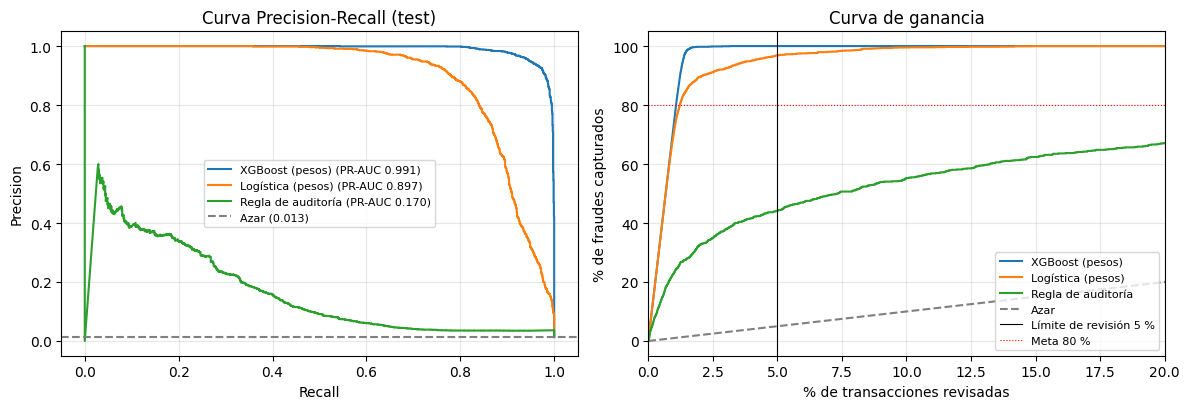

,transacciones,fraudes,tasa,lift,recall_acumulado
decil,,,,,
1,12358,1654,0.1338,10.0000,1.0000
2,12358,0,0.0000,0.0000,1.0000
3,12358,0,0.0000,0.0000,1.0000
4,12358,0,0.0000,0.0000,1.0000
5,12358,0,0.0000,0.0000,1.0000
6,12358,0,0.0000,0.0000,1.0000
7,12358,0,0.0000,0.0000,1.0000
8,12358,0,0.0000,0.0000,1.0000
9,12358,0,0.0000,0.0000,1.0000


In [14]:
comparar = list(dict.fromkeys([CHOSEN, 'Logística (pesos)', 'Regla de auditoría']))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name in comparar:
    p, r, _ = precision_recall_curve(y_test, test_scores[name])
    ax[0].plot(r, p, label=f"{name} (PR-AUC {test_df.loc[name, 'PR_AUC']:.3f})")
ax[0].axhline(y_test.mean(), ls='--', color='grey', label=f'Azar ({y_test.mean():.3f})')
ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precision'); ax[0].set_title('Curva Precision-Recall (test)')
ax[0].legend(fontsize=8)
for name in comparar:
    order = np.argsort(-test_scores[name], kind='mergesort')
    gain = np.cumsum(y_test.values[order]) / y_test.sum()
    ax[1].plot(np.arange(1, len(gain) + 1) / len(gain) * 100, gain * 100, label=name)
ax[1].plot([0, 100], [0, 100], ls='--', color='grey', label='Azar')
ax[1].axvline(5, color='black', lw=.8, label='Límite de revisión 5 %')
ax[1].axhline(80, color='red', lw=.8, ls=':', label='Meta 80 %')
ax[1].set_xlim(0, 20)
ax[1].set_xlabel('% de transacciones revisadas'); ax[1].set_ylabel('% de fraudes capturados')
ax[1].set_title('Curva de ganancia'); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / 'fig_pr_ganancia.png', dpi=160, bbox_inches='tight'); plt.show()

# Deciles de riesgo del modelo elegido
dec = pd.DataFrame({'y': y_test.values, 's': test_scores[CHOSEN]}).sort_values('s', ascending=False).reset_index(drop=True)
dec['decil'] = np.arange(len(dec)) * 10 // len(dec) + 1
lift = dec.groupby('decil').agg(transacciones=('y', 'size'), fraudes=('y', 'sum'), tasa=('y', 'mean'))
lift['lift'] = lift.tasa / y_test.mean()
lift['recall_acumulado'] = lift.fraudes.cumsum() / y_test.sum()
lift.to_csv(RESULTS / 'lift_deciles.csv')
lift

## 6. Sensibilidad: capacidad de revisión y monto capturado

Como el límite del 5 % resulta holgado para los mejores modelos, se estudia cuánto se podría reducir la revisión manual. Se calcula, para distintos niveles de revisión, el porcentaje de fraudes capturados y el porcentaje del **monto fraudulento** capturado (no todos los fraudes pesan igual), y el porcentaje mínimo de transacciones a revisar para alcanzar el 80 % de los fraudes.

Se comparan el modelo elegido, la logística (el modelo más simple) y la regla de auditoría. La revisión al azar captura en promedio el mismo porcentaje que revisa.

In [15]:
def k_para_recall(y_true, score, meta=0.80):
    order = np.argsort(-score, kind='mergesort')
    gain = np.cumsum(np.asarray(y_true)[order]) / np.sum(y_true)
    return (np.argmax(gain >= meta) + 1) / len(gain)

tasas = [0.0025, 0.005, 0.01, 0.015, 0.02, 0.03, 0.05]
monto_f = df.loc[X_test.index, 'amount'].values * y_test.values   # monto de las transacciones fraudulentas
nombres = list(dict.fromkeys([CHOSEN, 'Logística (pesos)', 'Regla de auditoría']))

rec, mon = {}, {}
for name in nombres:
    rec[name], mon[name] = [], []
    for k in tasas:
        m = top_k_mask(test_scores[name], k)
        rec[name].append(y_test.values[m].sum() / y_test.sum())
        mon[name].append(monto_f[m].sum() / monto_f.sum())

idx = [f'{k:.2%}' for k in tasas]
rec_df = pd.DataFrame(rec, index=idx); rec_df['Azar'] = tasas
mon_df = pd.DataFrame(mon, index=idx)
rec_df.index.name = mon_df.index.name = 'Transacciones revisadas'
rec_df.to_csv(RESULTS / 'recall_por_nivel_revision.csv')
mon_df.to_csv(RESULTS / 'monto_capturado_por_nivel_revision.csv')

print('Porcentaje de fraudes capturados según % de transacciones revisadas:')
display(rec_df)
print('Porcentaje del monto fraudulento capturado:')
display(mon_df)

k80 = pd.Series({n: k_para_recall(y_test, test_scores[n]) for n in nombres}, name='% a revisar para 80 % de fraudes')
print('Mínimo de transacciones a revisar para capturar el 80 % de los fraudes:')
display(k80.map('{:.2%}'.format))

Porcentaje de fraudes capturados según % de transacciones revisadas:


,XGBoost (pesos),Logística (pesos),Regla de auditoría,Azar
Transacciones revisadas,,,,
0.25%,0.1868,0.1868,0.0798,0.0025
0.50%,0.3736,0.3730,0.1385,0.0050
1.00%,0.7467,0.7116,0.2322,0.0100
1.50%,0.9861,0.8549,0.2793,0.0150
2.00%,0.9976,0.8954,0.3265,0.0200
3.00%,0.9994,0.9250,0.3785,0.0300
5.00%,1.0000,0.9686,0.4414,0.0500


Porcentaje del monto fraudulento capturado:


,XGBoost (pesos),Logística (pesos),Regla de auditoría
Transacciones revisadas,,,
0.25%,0.5007,0.7482,0.4066
0.50%,0.8586,0.9051,0.5420
1.00%,0.9730,0.9780,0.6557
1.50%,0.9994,0.9915,0.6924
2.00%,1.0000,0.9948,0.7201
3.00%,1.0000,0.9971,0.7439
5.00%,1.0000,0.9990,0.7656


Mínimo de transacciones a revisar para capturar el 80 % de los fraudes:


,% a revisar para 80 % de fraudes
XGBoost (pesos),1.07%
Logística (pesos),1.22%
Regla de auditoría,30.21%


## 7. Interpretabilidad con SHAP

Se explica el **modelo elegido** sobre una muestra del **test** con 400 transacciones fraudulentas y 400 legítimas, para ver qué variables distinguen a unas de otras. Las columnas one-hot se suman por variable original para presentar conceptos comprensibles para auditoría.

- Global: `mean(|SHAP|)` por variable original.
- Local: una transacción fraudulenta real del test; **valor esperado del output del modelo + suma de contribuciones = score del modelo**.
- Para XGBoost, SHAP se expresa en log-odds. En este proyecto el score se usa para ranking; para usarlo como probabilidad absoluta habría que evaluar calibración explícitamente.
- SHAP explica cómo razona el modelo; **no demuestra causalidad**.

Escala de SHAP: log-odds | valor esperado del output del modelo: 0.6198


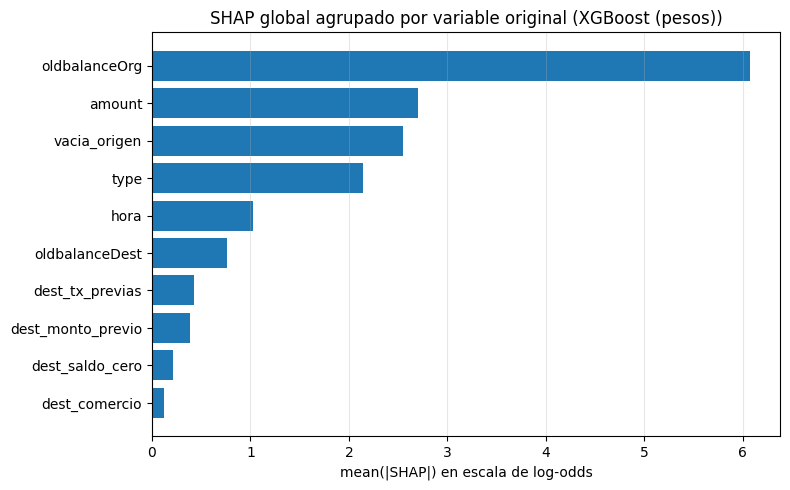

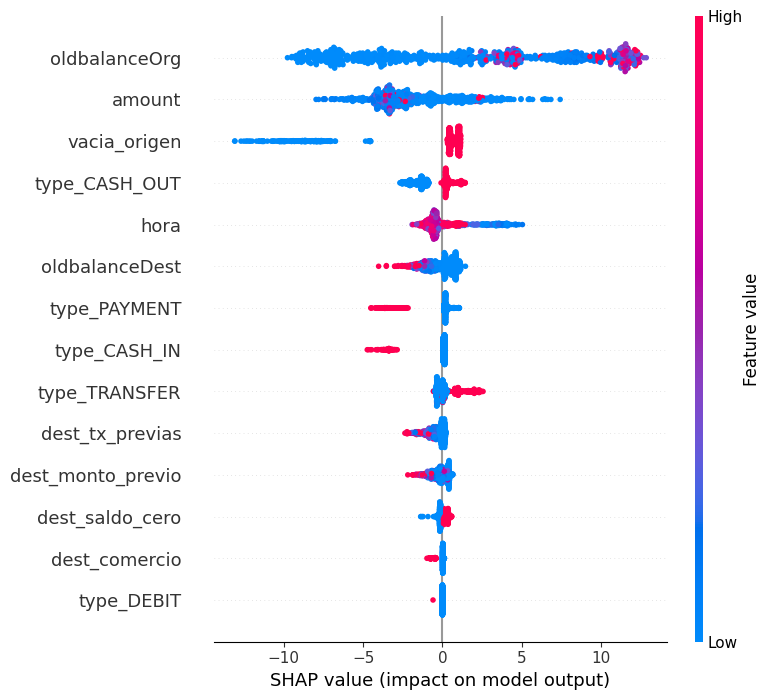

,mean_abs_shap,direccion_media
oldbalanceOrg,6.0740,1.8163
amount,2.6982,-1.7187
vacia_origen,2.5489,-1.3345
type,2.1414,-1.0289
hora,1.0214,0.1308
oldbalanceDest,0.7624,-0.1837
dest_tx_previas,0.4239,-0.3680
dest_monto_previo,0.3874,-0.1613
dest_saldo_cero,0.2131,0.0433
dest_comercio,0.1245,-0.0701


In [16]:
pipe = fitted[CHOSEN]
pre, model = pipe.named_steps['pre'], pipe.named_steps['model']
feature_names = pre.get_feature_names_out()

def original_var(fname):
    for c in cat_cols:
        if fname.startswith(c + '_'):
            return c
    return fname
groups = np.array([original_var(f) for f in feature_names])

pos = np.where(y_test.values == 1)[0]; neg = np.where(y_test.values == 0)[0]
sample_idx = np.concatenate([rng.choice(pos, 400, replace=False), rng.choice(neg, 400, replace=False)])
Xt_sample = pre.transform(X_test.iloc[sample_idx])
if 'Logística' in CHOSEN:
    explainer = shap.LinearExplainer(model, pre.transform(X_train.sample(2000, random_state=RANDOM_STATE)))
    link_note = 'log-odds'
else:
    explainer = shap.TreeExplainer(model)
    link_note = 'probabilidad' if 'Random Forest' in CHOSEN else 'log-odds'

def shap_values(Xt):
    e = explainer(Xt)
    v, b = np.asarray(e.values), np.asarray(e.base_values)
    if v.ndim == 3: v = v[:, :, 1]
    if b.ndim == 2: b = b[:, 1]
    return v, np.ravel(b)

values, base_values = shap_values(Xt_sample)
grouped = pd.DataFrame(values, columns=groups).T.groupby(level=0).sum().T   # suma por variable original
shap_global = grouped.abs().mean().sort_values(ascending=False).rename('mean_abs_shap').to_frame()
shap_global['direccion_media'] = grouped.mean().reindex(shap_global.index)
shap_global.to_csv(RESULTS / 'shap_global.csv')
print('Escala de SHAP:', link_note, '| valor esperado del output del modelo:', round(float(base_values[0]), 4))

fig, ax = plt.subplots(figsize=(8, 5))
top = shap_global.head(12).iloc[::-1]
ax.barh(top.index, top.mean_abs_shap, color='#1f77b4')
ax.set_title(f'SHAP global agrupado por variable original ({CHOSEN})')
ax.set_xlabel(f'mean(|SHAP|) en escala de {link_note}'); ax.grid(axis='x', alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / 'fig_shap_global.png', dpi=160, bbox_inches='tight'); plt.show()

shap.summary_plot(values, Xt_sample, feature_names=feature_names, show=False, max_display=15)
plt.tight_layout(); plt.savefig(RESULTS / 'shap_summary_dummies.png', dpi=160, bbox_inches='tight'); plt.show()
shap_global.head(12)

Valor esperado del output: 0.6198 | suma SHAP: +8.0650 | base + suma: 8.6848 | score del modelo: 0.9998


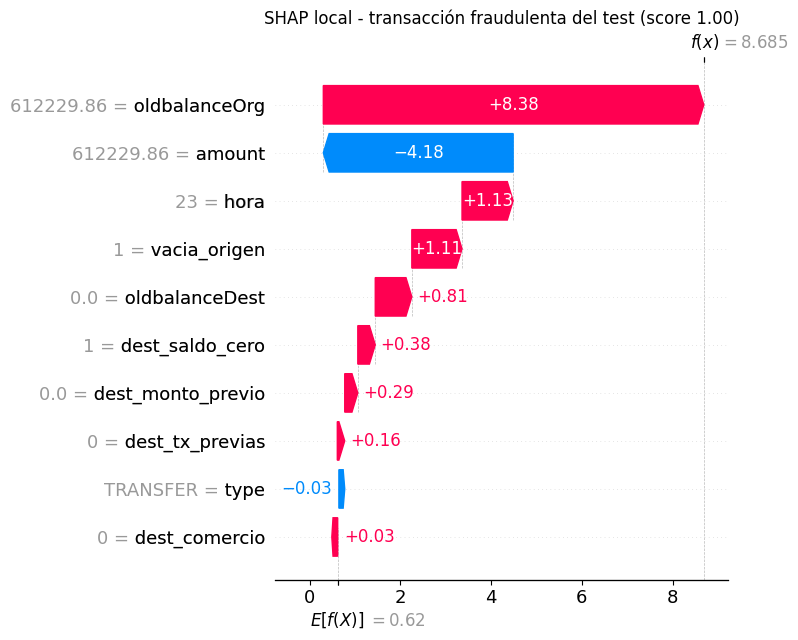

,shap,valor
oldbalanceOrg,8.3818,612229.86
amount,-4.1817,612229.86
hora,1.1262,23
vacia_origen,1.1057,1
oldbalanceDest,0.8055,0.0
dest_saldo_cero,0.3844,1
dest_monto_previo,0.2883,0.0
dest_tx_previas,0.1633,0
type,-0.0349,TRANSFER
dest_comercio,0.0265,0


In [17]:
# Caso local: un fraude real dentro del 5 % de mayor riesgo, con score cercano a la mediana de ese grupo
s = test_scores[CHOSEN]
in_top = top_k_mask(s)
cands = np.where(in_top & (y_test.values == 1))[0]
median_top = np.median(s[cands])
case_pos = int(cands[np.argmin(np.abs(s[cands] - median_top))])
row = X_test.iloc[[case_pos]]
v_case, b_case = shap_values(pre.transform(row))
local = (pd.Series(v_case[0], index=groups).groupby(level=0).sum()
         .rename('shap').to_frame())
local['valor'] = [str(row.iloc[0][c]) for c in local.index]
local = local.reindex(local.shap.abs().sort_values(ascending=False).index)
local.to_csv(RESULTS / 'shap_local_case.csv')

score_model = s[case_pos]
print(f'Valor esperado del output: {b_case[0]:.4f} | suma SHAP: {local.shap.sum():+.4f} | '
      f'base + suma: {b_case[0] + local.shap.sum():.4f} | score del modelo: {score_model:.4f}')

exp = shap.Explanation(values=local.shap.values, base_values=float(b_case[0]),
                       data=local.valor.values, feature_names=local.index.tolist())
shap.plots.waterfall(exp, max_display=10, show=False)
plt.title(f'SHAP local - transacción fraudulenta del test (score {score_model:.2f})')
plt.tight_layout(); plt.savefig(RESULTS / 'fig_shap_local.png', dpi=160, bbox_inches='tight'); plt.show()
local.head(10)

## 8. Profundización

Esta sección pone a prueba el modelo elegido desde cuatro ángulos: qué bloques de variables aportan valor (ablaciones), si el desempeño se sostiene a lo largo de los días del test, cómo se vería el trabajo del auditor con la prevalencia real de fraude (0,13 %) y si conviene ordenar por **pérdida esperada** (probabilidad × monto) en vez de solo por probabilidad.

### 8.1 Ablaciones de hipótesis
Se reentrena el modelo elegido **sin** un bloque de variables y se mide la caída sobre el mismo test.

- **H1** historial del destinatario: `dest_tx_previas`, `dest_monto_previo`.
- **H2** patrón de vaciado de cuenta: `vacia_origen`.
- **H3** hora del día: `hora`.
- **H4** saldo del destinatario: `oldbalanceDest`, `dest_saldo_cero`.
- **H5** tipo de transacción: `type`.

In [18]:
def make_pre_cols(cats, nums, scale):
    return ColumnTransformer(
        [('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cats),
         ('num', StandardScaler() if scale else 'passthrough', nums)],
        verbose_feature_names_out=False)

def r_precision(y_true, score):
    # De los F transacciones mejor rankeadas (F = fraudes reales), cuántas son fraude.
    # No depende de la tasa de fraude del tramo, a diferencia de Recall@k.
    y_true = np.asarray(y_true); F = int(y_true.sum())
    if F == 0:
        return np.nan
    top = np.argsort(-np.asarray(score), kind='mergesort')[:F]
    return float(y_true[top].mean())

base_s = test_scores[CHOSEN]
base_m = {'PR_AUC': float(average_precision_score(y_test, base_s)),
          'Recall@1%': float(recall_at_k(y_test, base_s, 0.01))}
print('Modelo completo:', {k: round(v, 4) for k, v in base_m.items()})

Modelo completo: {'PR_AUC': 0.9909, 'Recall@1%': 0.7467}


In [19]:
blocks = {
    'H1 - sin historial del destinatario': ['dest_tx_previas', 'dest_monto_previo'],
    'H2 - sin patrón de vaciado':          ['vacia_origen'],
    'H3 - sin hora del día':               ['hora'],
    'H4 - sin saldo del destinatario':     ['oldbalanceDest', 'dest_saldo_cero'],
    'H5 - sin tipo de transacción':        ['type'],
}
es_logistica = 'Logística' in CHOSEN
abl_rows = [{'escenario': 'Modelo completo', **base_m, 'delta_PR_AUC': 0.0, 'delta_Recall@1%': 0.0}]

for label, cols in blocks.items():
    cats = [c for c in cat_cols if c not in cols]
    nums = [c for c in num_cols if c not in cols]
    pipe_a = Pipeline([('pre', make_pre_cols(cats, nums, es_logistica)),
                       ('model', clone(fitted[CHOSEN].named_steps['model']))])
    pipe_a.fit(X_train[cats + nums], y_train)
    s_a = pipe_a.predict_proba(X_test[cats + nums])[:, 1]
    m_a = {'PR_AUC': average_precision_score(y_test, s_a),
           'Recall@1%': recall_at_k(y_test, s_a, 0.01)}
    abl_rows.append({'escenario': label, **m_a,
                     'delta_PR_AUC': m_a['PR_AUC'] - base_m['PR_AUC'],
                     'delta_Recall@1%': m_a['Recall@1%'] - base_m['Recall@1%']})
    print('listo:', label)

abl_df = pd.DataFrame(abl_rows).set_index('escenario')
abl_df.to_csv(RESULTS / 'ablaciones.csv')
abl_df

listo: H1 - sin historial del destinatario
listo: H2 - sin patrón de vaciado
listo: H3 - sin hora del día
listo: H4 - sin saldo del destinatario
listo: H5 - sin tipo de transacción


,PR_AUC,Recall@1%,delta_PR_AUC,delta_Recall@1%
escenario,,,,
Modelo completo,0.9909,0.7467,0.0000,0.0000
H1 - sin historial del destinatario,0.9920,0.7449,0.0011,-0.0018
H2 - sin patrón de vaciado,0.9679,0.7412,-0.0230,-0.0054
H3 - sin hora del día,0.9890,0.7455,-0.0019,-0.0012
H4 - sin saldo del destinatario,0.9900,0.7461,-0.0010,-0.0006
H5 - sin tipo de transacción,0.9824,0.7394,-0.0085,-0.0073


### 8.2 Estabilidad por día dentro del test
Se evalúa el modelo elegido día por día. Como la tasa de fraude cambia mucho entre días (el volumen legítimo cae hacia el final de la simulación mientras los fraudes se mantienen), se usa **R-precision** además de PR-AUC: de las *F* transacciones mejor rankeadas, donde *F* es el número real de fraudes del día, cuántas son fraude. Esta métrica no depende de la tasa de fraude del día. El último día es casi todo fraude, por lo que sus métricas son triviales y no deben usarse como evidencia.

In [20]:
dia_test = ((df.loc[X_test.index, 'step'] - 1) // 24 + 1).values
rows = []
for d in np.unique(dia_test):
    m = dia_test == d
    yd, sd = y_test.values[m], base_s[m]
    rows.append({'día': int(d), 'transacciones': int(m.sum()), 'fraudes': int(yd.sum()),
                 'tasa_fraude': yd.mean(),
                 'PR_AUC': average_precision_score(yd, sd) if 0 < yd.sum() < len(yd) else np.nan,
                 'R_precision': r_precision(yd, sd)})
por_dia_test = pd.DataFrame(rows).set_index('día')
por_dia_test.to_csv(RESULTS / 'metricas_por_dia_test.csv')
por_dia_test

,transacciones,fraudes,tasa_fraude,PR_AUC,R_precision
día,,,,,
25,20007,54,0.0027,0.9897,0.9259
26,13885,272,0.0196,0.9948,0.9596
27,8578,280,0.0326,0.9977,0.9714
28,14661,248,0.0169,0.9859,0.9234
29,54890,260,0.0047,0.9809,0.9308
30,11287,268,0.0237,0.9942,0.9664
31,272,272,1.0000,NaN,1.0000


### 8.3 Desempeño con la prevalencia real de fraude
En el test el fraude es 1,34 %, pero en el total del dataset es 0,13 %. Para estimar cómo se vería la carga del auditor con la prevalencia real, se toma el punto de la curva donde se alcanza un recall objetivo y se calculan, sobre 1.000.000 de transacciones con 0,13 % de fraude, las **transacciones a revisar**, la **precisión** y los **falsos positivos por fraude detectado**.

In [21]:
PREV_REAL = df_raw.isFraud.mean()

def operar_a_prevalencia(y_true, score, recall_meta, prev=PREV_REAL, N=1_000_000):
    y = np.asarray(y_true)
    ys = y[np.argsort(-np.asarray(score), kind='mergesort')]
    tp, fp = np.cumsum(ys), np.cumsum(1 - ys)
    i = int(np.argmax(tp / ys.sum() >= recall_meta))
    tpr, fpr = tp[i] / ys.sum(), fp[i] / (1 - ys).sum()
    F = prev * N
    TP, FP = tpr * F, fpr * (N - F)
    return {'recall_meta': recall_meta,
            '% a revisar': (TP + FP) / N,
            'precisión': TP / (TP + FP),
            'falsos positivos por fraude detectado': FP / TP}

filas = []
for n in nombres:
    for meta in [0.80, 0.90]:
        filas.append({'modelo': n, **operar_a_prevalencia(y_test, test_scores[n], meta)})
prev_df = pd.DataFrame(filas).set_index('modelo')
prev_df.to_csv(RESULTS / 'operacion_prevalencia_real.csv')
print(f'Prevalencia real usada: {PREV_REAL:.4%}')
prev_df

Prevalencia real usada: 0.1291%


,recall_meta,% a revisar,precisión,falsos positivos por fraude detectado
modelo,,,,
XGBoost (pesos),0.8000,0.0010,0.9844,0.0159
XGBoost (pesos),0.9000,0.0014,0.8113,0.2326
Logística (pesos),0.8000,0.0025,0.4107,1.4348
Logística (pesos),0.9000,0.0104,0.1122,7.9088
Regla de auditoría,0.8000,0.2960,0.0035,285.5011
Regla de auditoría,0.9000,0.3360,0.0035,288.1214


In [22]:
def bootstrap_operacion(y_true, score, recall_meta, B=300, seed=42):
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y_true), np.asarray(score)
    res = []
    for _ in range(B):
        idx = rng.integers(0, len(y), len(y))
        res.append(operar_a_prevalencia(y[idx], s[idx], recall_meta))
    r = pd.DataFrame(res)
    return r.quantile([0.025, 0.5, 0.975]).T.rename(
        columns={0.025: 'IC95 inf', 0.5: 'mediana', 0.975: 'IC95 sup'})

for meta in [0.80, 0.90]:
    print(f'Recall objetivo {meta:.0%} (XGBoost, intervalo de confianza 95 %):')
    display(bootstrap_operacion(y_test, test_scores[CHOSEN], meta))

Recall objetivo 80% (XGBoost, intervalo de confianza 95 %):


,IC95 inf,mediana,IC95 sup
recall_meta,0.8000,0.8000,0.8000
% a revisar,0.0010,0.0011,0.0011
precisión,0.9403,0.9768,1.0000
falsos positivos por fraude detectado,0.0000,0.0238,0.0634


Recall objetivo 90% (XGBoost, intervalo de confianza 95 %):


,IC95 inf,mediana,IC95 sup
recall_meta,0.9000,0.9000,0.9000
% a revisar,0.0013,0.0014,0.0016
precisión,0.7472,0.8113,0.8793
falsos positivos por fraude detectado,0.1373,0.2326,0.3383


### 8.4 Ranking por pérdida esperada
Ordenar solo por probabilidad trata igual a un fraude chico y a uno grande. Se compara el ranking por probabilidad con el ranking por **probabilidad × monto** (pérdida esperada), midiendo qué porcentaje de fraudes y qué porcentaje del **monto** fraudulento se captura según cuánto se revise.

In [23]:
monto_test = X_test['amount'].values
y_arr = y_test.values
rankings = {
    'Regla de auditoría':         test_scores['Regla de auditoría'],
    f'{CHOSEN} (prob.)':          test_scores[CHOSEN],
    f'{CHOSEN} (prob. × monto)':  test_scores[CHOSEN] * monto_test,
}
tasas_pe = [0.0025, 0.005, 0.01, 0.015, 0.02, 0.03, 0.05]
cap_n, cap_m = {}, {}
for n, s in rankings.items():
    cap_n[n], cap_m[n] = [], []
    for k in tasas_pe:
        m = top_k_mask(s, k)
        cap_n[n].append(y_arr[m].sum() / y_arr.sum())
        cap_m[n].append(monto_test[m & (y_arr == 1)].sum() / monto_test[y_arr == 1].sum())

idx = [f'{k:.2%}' for k in tasas_pe]
cap_n_df, cap_m_df = pd.DataFrame(cap_n, index=idx), pd.DataFrame(cap_m, index=idx)
cap_n_df.index.name = cap_m_df.index.name = 'Transacciones revisadas'
cap_n_df.to_csv(RESULTS / 'ranking_fraudes_capturados.csv')
cap_m_df.to_csv(RESULTS / 'ranking_monto_capturado.csv')
print('% de fraudes capturados:');            display(cap_n_df)
print('% del monto fraudulento capturado:');   display(cap_m_df)

% de fraudes capturados:


,Regla de auditoría,XGBoost (pesos) (prob.),XGBoost (pesos) (prob. × monto)
Transacciones revisadas,,,
0.25%,0.0798,0.1868,0.1868
0.50%,0.1385,0.3736,0.3736
1.00%,0.2322,0.7467,0.7116
1.50%,0.2793,0.9861,0.9305
2.00%,0.3265,0.9976,0.9813
3.00%,0.3785,0.9994,0.9897
5.00%,0.4414,1.0000,0.9940


% del monto fraudulento capturado:


,Regla de auditoría,XGBoost (pesos) (prob.),XGBoost (pesos) (prob. × monto)
Transacciones revisadas,,,
0.25%,0.4066,0.5007,0.7497
0.50%,0.5420,0.8586,0.9079
1.00%,0.6557,0.9730,0.9882
1.50%,0.6924,0.9994,0.9994
2.00%,0.7201,1.0000,1.0000
3.00%,0.7439,1.0000,1.0000
5.00%,0.7656,1.0000,1.0000


### 8.5 Auditoría por grupos
PaySim es sintético y **no tiene atributos demográficos**, por lo que no se puede auditar sesgo por edad, género u otras características de las personas. Lo que sí se puede revisar es si el modelo concentra la revisión (y, sobre todo, los **falsos positivos**, que son los clientes legítimos molestados) en ciertos tipos de transacción, rangos de monto u horarios. Se usa un punto de operación `K_OP` con margen sobre el mínimo hallado en la sección 6 (≈1,07 %); ajustar según la capacidad real del equipo.

In [24]:
K_OP = 0.02   # punto de operación propuesto: 2 % de las transacciones a revisión

def auditoria(valores, nombre, k=K_OP):
    t = pd.DataFrame({'grupo': np.asarray(valores), 'y': y_arr,
                      'rev': top_k_mask(test_scores[CHOSEN], k)})
    g = t.groupby('grupo', observed=True)
    out = pd.DataFrame({
        'transacciones': g.size(),
        'participación': g.size() / len(t),
        'tasa_fraude': g.y.mean(),
        '% revisadas': g.rev.mean(),
        'recall': t[t.y == 1].groupby('grupo', observed=True).rev.mean(),
        '% falsos positivos': t[t.y == 0].groupby('grupo', observed=True).rev.mean()})
    out.insert(0, 'atributo', nombre)
    return out

franja = pd.cut(X_test['hora'], [-1, 5, 11, 17, 23],
                labels=['madrugada', 'mañana', 'tarde', 'noche'])
audit = pd.concat([
    auditoria(X_test['type'], 'tipo'),
    auditoria(pd.qcut(X_test['amount'], 5, labels=['Q1 (menor)', 'Q2', 'Q3', 'Q4', 'Q5 (mayor)'], duplicates='drop').astype(str), 'quintil de monto'),
    auditoria(franja.astype(str), 'franja horaria'),
])
audit.to_csv(RESULTS / 'auditoria_grupos.csv')
audit

,atributo,transacciones,participación,tasa_fraude,% revisadas,recall,% falsos positivos
grupo,,,,,,,
CASH_IN,tipo,28378,0.2296,0.0000,0.0000,NaN,0.0000
CASH_OUT,tipo,39257,0.3177,0.0211,0.0399,0.9952,0.0194
DEBIT,tipo,989,0.0080,0.0000,0.0000,NaN,0.0000
PAYMENT,tipo,42927,0.3474,0.0000,0.0000,NaN,0.0000
TRANSFER,tipo,12029,0.0973,0.0688,0.0752,1.0000,0.0070
Q1 (menor),quintil de monto,24716,0.2000,0.0018,0.0034,0.9091,0.0018
Q2,quintil de monto,24716,0.2000,0.0027,0.0078,1.0000,0.0051
Q3,quintil de monto,24716,0.2000,0.0119,0.0255,1.0000,0.0138
Q4,quintil de monto,24716,0.2000,0.0076,0.0151,1.0000,0.0076


## 9. Traducción a negocio: escenario económico (paramétrico)

**Los montos y los costos se expresan en unidades monetarias del simulador, porque PaySim no informa moneda. Todos los valores de costos son supuestos ilustrativos, no datos reales** (PaySim no informa moneda ni costos operativos; reemplazarlos por los de la organización):

- `COSTO_REVISION`: costo de que un analista revise una transacción.
- `COSTO_FP`: fricción por bloquear o demorar a un cliente legítimo.
- `TASA_RECUPERO`: fracción del monto fraudulento que se evita o recupera cuando el fraude se detecta a tiempo.

Beneficio neto = `TASA_RECUPERO × monto fraudulento capturado − COSTO_REVISION × transacciones revisadas − COSTO_FP × falsos positivos`.

Se calcula para el período de test y para tres criterios de ranking, y se busca el nivel de revisión que maximiza el beneficio. **Advertencia:** la prevalencia del test (1,34 %) es unas 10 veces la real, así que el beneficio absoluto está sobreestimado y el costo de revisar pesaría más en producción. Por eso se incluye una sensibilidad al costo de revisión.

,revisadas,monto_capturado,falsos_positivos,beneficio_neto,% pérdida evitada
Ranking (revisando 2%),,,,,
Regla de auditoría,"2,472.0000","1,960,455,952.1300","1,932.0000","1,564,926,761.7040",0.5761
XGBoost (pesos) (prob.),"2,472.0000","2,722,429,297.9000",822.0000,"2,175,060,438.3200",0.8000
XGBoost (pesos) (prob. × monto),"2,472.0000","2,722,328,720.0800",849.0000,"2,174,966,476.0640",0.8000


,k óptimo,beneficio neto máx.
Regla de auditoría,0.3680,"2,110,237,919.4240"
XGBoost (pesos) (prob.),0.0170,"2,175,497,493.2080"
XGBoost (pesos) (prob. × monto),0.0170,"2,175,209,155.8960"


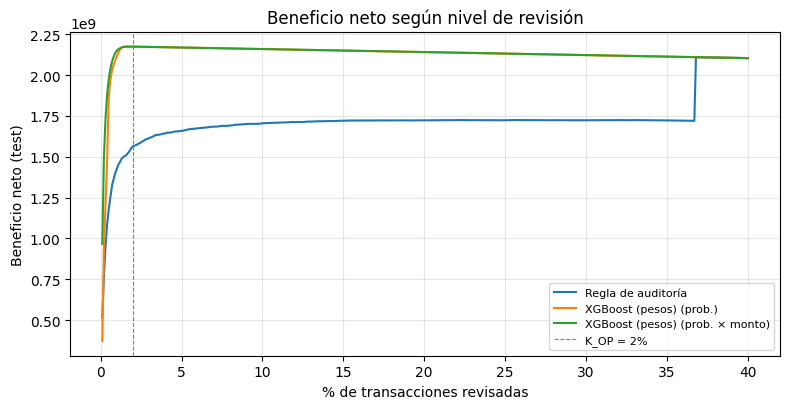

,k óptimo,beneficio neto máx.
costo_revision,,
250,0.0180,"2,176,876,948.7760"
1000,0.0170,"2,175,209,155.8960"
5000,0.0160,"2,167,157,690.4640"
20000,0.0140,"2,140,579,799.5920"
50000,0.0110,"2,093,794,939.5600"


In [25]:
COSTO_REVISION = 1_000    # supuesto
COSTO_FP       = 500      # supuesto
TASA_RECUPERO  = 0.80     # supuesto

perdida_total = monto_test[y_arr == 1].sum()

def beneficio(score, k, costo_rev=COSTO_REVISION):
    m = top_k_mask(score, k)
    capt = monto_test[m & (y_arr == 1)].sum()
    fp = int((m & (y_arr == 0)).sum())
    return {'revisadas': int(m.sum()), 'monto_capturado': capt, 'falsos_positivos': fp,
            'beneficio_neto': TASA_RECUPERO * capt - costo_rev * m.sum() - COSTO_FP * fp}

# Escenario en el punto de operación K_OP
econ = pd.DataFrame({n: beneficio(s, K_OP) for n, s in rankings.items()}).T
econ['% pérdida evitada'] = TASA_RECUPERO * econ['monto_capturado'] / perdida_total
econ.index.name = f'Ranking (revisando {K_OP:.0%})'
econ.to_csv(RESULTS / 'escenario_economico.csv')
display(econ)

# Curva de beneficio y nivel de revisión óptimo
grid = np.round(np.arange(0.001, 0.4001, 0.001), 4)
curvas = {n: np.array([beneficio(s, k)['beneficio_neto'] for k in grid]) for n, s in rankings.items()}
optimo = pd.DataFrame({n: {'k óptimo': grid[c.argmax()], 'beneficio neto máx.': c.max()}
                       for n, c in curvas.items()}).T
optimo.to_csv(RESULTS / 'nivel_revision_optimo.csv')
display(optimo)

fig, ax = plt.subplots(figsize=(8, 4.2))
for n, c in curvas.items():
    ax.plot(grid * 100, c, label=n)
ax.axvline(K_OP * 100, color='grey', ls='--', lw=.8, label=f'K_OP = {K_OP:.0%}')
ax.set_xlabel('% de transacciones revisadas'); ax.set_ylabel('Beneficio neto (test)')
ax.set_title('Beneficio neto según nivel de revisión'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / 'fig_beneficio_neto.png', dpi=160, bbox_inches='tight'); plt.show()

# Sensibilidad al costo de revisión (ranking por pérdida esperada)
nombre_pe = f'{CHOSEN} (prob. × monto)'
sens = []
for cr in [250, 1_000, 5_000, 20_000, 50_000]:
    cs = np.array([beneficio(rankings[nombre_pe], k, cr)['beneficio_neto'] for k in grid])
    sens.append({'costo_revision': cr, 'k óptimo': grid[cs.argmax()], 'beneficio neto máx.': cs.max()})
sens_df = pd.DataFrame(sens).set_index('costo_revision')
sens_df.to_csv(RESULTS / 'sensibilidad_costo_revision.csv')
sens_df

## 10. Ética, privacidad y limitaciones

**Datos y privacidad.** PaySim es sintético: no contiene datos personales y los identificadores de cuenta son códigos simulados. Con datos reales de una entidad financiera habría que aplicar la Ley 25.326 de Protección de Datos Personales y la normativa del regulador: minimización de datos, pseudonimización, control de accesos y trazabilidad de quién consulta los scores.

**Falsos positivos y trato justo.** Cada falsa alarma es un cliente legítimo potencialmente bloqueado o demorado. El modelo prioriza ordenar casos para **revisión humana**, no bloquear automáticamente. La sección 8.5 audita los falsos positivos por tipo, monto y horario; con datos reales habría que auditar también por atributos protegidos y por segmentos de clientes.

**Explicabilidad.** SHAP permite justificar por qué una transacción quedó alta en el ranking. Describe cómo razona el modelo y no demuestra causalidad.

**Limitaciones.**
1. *Datos sintéticos y de ~31 días:* no capturan estacionalidad ni la evolución de las tácticas de fraude. Se usan por su volumen (6,36 M de transacciones, 8.213 fraudes), pero los resultados no se pueden extrapolar sin validar con datos reales.
2. *Artefacto de la simulación:* la tasa de fraude sube de 0,08 % (train) a 1,34 % (test) porque el volumen legítimo cae al final mientras los fraudes se mantienen. Las métricas casi perfectas están infladas por ese contexto; por eso se reportan contra pisos, por día y con la prevalencia real (8.2 y 8.3).
3. *Adversarios adaptativos:* los defraudadores cambian de conducta al detectar controles, lo que degrada el modelo con el tiempo.
4. *Costos supuestos:* el escenario económico usa parámetros ilustrativos.



## 11. Despliegue y monitoreo (fase final de CRISP-DM)

- **Uso:** el modelo puntúa cada lote (por ejemplo, por hora o día) y el equipo revisa el top *k* % de mayor pérdida esperada. Se usa un ranking por lote y no un umbral de probabilidad fijo, porque la prevalencia cambia mucho entre períodos (0,08 % → 1,34 %).
- **Monitoreo:** seguir semanalmente la tasa de fraude confirmado, el recall sobre los casos confirmados, la precisión del top *k* y la distribución de los scores y de las variables de entrada (drift).
- **Reentrenamiento:** periódico y ante señales de drift, con las etiquetas confirmadas por el equipo de auditoría.
- **Piloto antes del despliegue:** correr el modelo en paralelo al proceso actual, sin cambiar decisiones, y comparar contra la regla de auditoría.

## 12. Resumen de resultados

In [26]:
resumen = {
    'modelo_elegido': CHOSEN,
    'valid_PR_AUC': round(valid_df.loc[CHOSEN, 'PR_AUC'], 4),
    'test_PR_AUC': round(test_df.loc[CHOSEN, 'PR_AUC'], 4),
    'test_Recall@5%': round(test_df.loc[CHOSEN, 'Recall@5'], 4),
    'test_Recall@1%': round(recall_at_k(y_test, test_scores[CHOSEN], 0.01), 4),
    'pct_a_revisar_para_80pct_modelo': round(float(k80[CHOSEN]), 4),
    'pct_a_revisar_para_80pct_regla': round(float(k80['Regla de auditoría']), 4),
    'tasa_fraude_train': round(y_train.mean(), 5),
    'tasa_fraude_valid': round(y_valid.mean(), 5),
    'tasa_fraude_test': round(y_test.mean(), 5),
    'k_optimo_economico_prob_x_monto': float(optimo.loc[nombre_pe, 'k óptimo']),
    'beneficio_neto_max_prob_x_monto': round(float(optimo.loc[nombre_pe, 'beneficio neto máx.']), 0),
}
pd.Series(resumen).to_csv(RESULTS / 'resumen.csv', header=['valor'])
pd.Series(resumen)

,0
modelo_elegido,XGBoost (pesos)
valid_PR_AUC,0.9863
test_PR_AUC,0.9909
test_Recall@5%,1.0000
test_Recall@1%,0.7467
pct_a_revisar_para_80pct_modelo,0.0107
pct_a_revisar_para_80pct_regla,0.3021
tasa_fraude_train,0.0008
tasa_fraude_valid,0.0068
tasa_fraude_test,0.0134


**Conclusión.** El modelo elegido por la regla ex ante, **XGBoost con ponderación de clases**, ordena las transacciones por riesgo mucho mejor que las alternativas: en el test temporal alcanza una PR-AUC de 0,991 (contra un piso de 0,013) y captura el 100 % de los fraudes revisando el 5 % de las transacciones, con lo que cumple el KPI con holgura. Para llegar al 80 % de los fraudes necesita revisar apenas el 1,07 % de las transacciones, frente al 30,2 % de la regla simple de auditoría.

Dos matices acotan este resultado. Primero, el techo de las métricas es en parte resultado de la simulación (la tasa de fraude del test es 10 veces la real y el último día es casi todo fraude), así que el resultado debe leerse como evidencia de que el patrón es detectable y no como la precisión esperable en producción; por día, la R-precision va de 0,92 a 0,97. Con la prevalencia real, alcanzar el 80 % de recall implicaría revisar cerca del 0,10 % de las transacciones, con entre 0 y 0,06 falsos positivos por fraude detectado (IC 95 %; la regla de auditoría necesita revisar el 29,6 % y genera unos 286), una estimación que descansa en muy pocos falsos positivos y por eso se reporta con su intervalo. Segundo, las ablaciones indican que el patrón de vaciado de cuenta y el tipo de transacción son los bloques más valiosos; el historial del destinatario, la hora y el saldo del destinatario aportan menos de 0,002 de PR-AUC, dentro del ruido.

En términos de negocio, ordenar por pérdida esperada (probabilidad × monto) captura mucho más monto cuando la capacidad de revisión es muy baja (75 % contra 50 % revisando el 0,25 %), pero con presupuestos cercanos al óptimo ambos criterios capturan casi el 100 % del monto y el beneficio neto es prácticamente igual. El nivel de revisión que maximiza el beneficio, bajo los supuestos de costos indicados, es 1,7 % del test, unas 1,3 veces la tasa de fraude de ese período.

**Recomendación:** pilotear el modelo en paralelo al proceso actual, con ranking por lote y revisión humana de los casos de mayor pérdida esperada. Monitorear drift y recall semanalmente, reentrenar con las etiquetas confirmadas y recalibrar el escenario económico con costos reales antes de cualquier decisión de inversión.